# Crack Classification — ConvNeXt V2-Tiny (Corrected)

Binary classification: **crack vs no_crack**.

Dataset:
- 40,000 images
- 28,000 train
- 8,000 validation
- 4,000 test

Model:
- `convnextv2_tiny.fcmae_ft_in22k_in1k`
- ImageNet-pretrained weights
- PyTorch + timm

This version fixes the failed training workflow by using a conservative learning rate, gradient clipping, explicit NaN/Inf checks, fresh-run checkpoint control, and a safer Grad-CAM section.

## Expected dataset structure

```text
DATA_DIR/
├── train/
│   ├── crack/
│   └── no_crack/
├── val/
│   ├── crack/
│   └── no_crack/
└── test/
    ├── crack/
    └── no_crack/
```

The notebook detects the class indices from `ImageFolder`; it does not assume that crack is class 0.

## 1. Setup — install and import

In [1]:
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "timm", "scikit-learn", "seaborn", "grad-cam", "pillow"
])

print("Python:", sys.executable)

Python: C:\Users\Students\AppData\Local\Programs\Python\Python310\python.exe


In [2]:
import os
import time
import json
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

import timm

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("timm:", timm.__version__)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

C:\Users\Students\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.11.0+cu130
timm: 1.0.29
Device: cuda
GPU: NVIDIA GeForce RTX 5070


## 2. Configuration — edit only this cell if the path differs

In [3]:
# =========================
# USER CONFIGURATION
# =========================

DATA_DIR = r"C:\Users\Students\Desktop\Crack classification(Indhu)\classification\dataset"
OUTPUT_DIR = r"C:\Users\Students\Desktop\Crack classification(Indhu)\Output"

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0
EPOCHS = 15

# Conservative LR for fine-tuning a pretrained ConvNeXt V2 model.
LR = 1e-4
WEIGHT_DECAY = 1e-4

NUM_CLASSES = 2
MODEL_KEY = "convnext_v2_tiny"
TIMM_NAME = "convnextv2_tiny.fcmae_ft_in22k_in1k"
PRETRAINED = True

# Keep AMP OFF for the first clean run.
# It can be enabled later after stable training is confirmed.
USE_AMP = False

# Prevent exploding gradients.
GRAD_CLIP_NORM = 1.0

PATIENCE = 5

# IMPORTANT:
# False = always start a clean experiment.
# True = explicitly resume the saved checkpoint.
RESUME_TRAINING = False

# =========================

if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(f"DATA_DIR does not exist: {DATA_DIR}")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "checkpoints"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "logs"), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "figures"), exist_ok=True)

print("Dataset exists:", os.path.exists(DATA_DIR))
print("Output directory:", OUTPUT_DIR)
print("Learning rate:", LR)
print("AMP:", USE_AMP)

Dataset exists: True
Output directory: C:\Users\Students\Desktop\Crack classification(Indhu)\Output
Learning rate: 0.0001
AMP: False


## 3. Dataset analytics

In [4]:
def count_images(split_dir):
    counts = {}
    valid_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

    for class_name in ["crack", "no_crack"]:
        p = Path(split_dir) / class_name

        if p.exists():
            counts[class_name] = sum(
                1 for f in p.rglob("*")
                if f.is_file() and f.suffix.lower() in valid_exts
            )
        else:
            counts[class_name] = 0

    return counts

stats = {
    split: count_images(os.path.join(DATA_DIR, split))
    for split in ["train", "val", "test"]
}

stats_df = pd.DataFrame(stats).T
stats_df["total"] = stats_df.sum(axis=1)

print(stats_df)

expected = {"train": 28000, "val": 8000, "test": 4000}
for split, expected_total in expected.items():
    actual = int(stats_df.loc[split, "total"])
    if actual != expected_total:
        print(
            f"WARNING: {split} has {actual} images; "
            f"expected {expected_total}."
        )

       crack  no_crack  total
train  14000     14000  28000
val     4000      4000   8000
test    2000      2000   4000


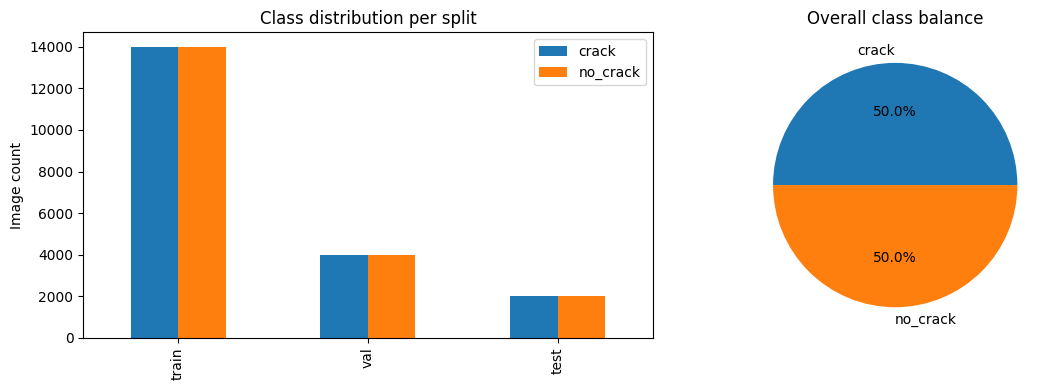

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

stats_df[["crack", "no_crack"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("Class distribution per split")
axes[0].set_ylabel("Image count")
axes[0].set_xlabel("")

totals = stats_df[["crack", "no_crack"]].sum()

axes[1].pie(
    totals,
    labels=totals.index,
    autopct="%1.1f%%"
)
axes[1].set_title("Overall class balance")

plt.tight_layout()
plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "figures",
        f"{MODEL_KEY}_dataset_analytics.png"
    ),
    dpi=150
)
plt.show()

## 4. Data loaders

In [6]:
# ImageNet normalization for the ImageNet-pretrained model.
train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_ds = datasets.ImageFolder(
    os.path.join(DATA_DIR, "train"),
    transform=train_tfms
)

val_ds = datasets.ImageFolder(
    os.path.join(DATA_DIR, "val"),
    transform=eval_tfms
)

test_ds = datasets.ImageFolder(
    os.path.join(DATA_DIR, "test"),
    transform=eval_tfms
)

CRACK_IDX = train_ds.class_to_idx["crack"]
NO_CRACK_IDX = train_ds.class_to_idx["no_crack"]

if val_ds.class_to_idx != train_ds.class_to_idx:
    raise ValueError(
        f"Train/val mapping mismatch: "
        f"{train_ds.class_to_idx} vs {val_ds.class_to_idx}"
    )

if test_ds.class_to_idx != train_ds.class_to_idx:
    raise ValueError(
        f"Train/test mapping mismatch: "
        f"{train_ds.class_to_idx} vs {test_ds.class_to_idx}"
    )

print("Class-to-index mapping:", train_ds.class_to_idx)
print("CRACK_IDX:", CRACK_IDX)
print("NO_CRACK_IDX:", NO_CRACK_IDX)
print(
    "Train / Val / Test sizes:",
    len(train_ds),
    len(val_ds),
    len(test_ds)
)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

Class-to-index mapping: {'crack': 0, 'no_crack': 1}
CRACK_IDX: 0
NO_CRACK_IDX: 1
Train / Val / Test sizes: 28000 8000 4000


## 5. Verify one training batch

In [7]:
images, labels = next(iter(train_loader))

print("Image batch shape:", tuple(images.shape))
print("Label batch shape:", tuple(labels.shape))
print("Image dtype:", images.dtype)
print("Labels:", torch.unique(labels).tolist())
print("Images finite:", bool(torch.isfinite(images).all()))

if not torch.isfinite(images).all():
    raise RuntimeError("Training images contain NaN or Inf.")

valid_labels = {CRACK_IDX, NO_CRACK_IDX}
observed_labels = set(torch.unique(labels).tolist())

if not observed_labels.issubset(valid_labels):
    raise RuntimeError(
        f"Unexpected labels found: {observed_labels}"
    )

Image batch shape: (32, 3, 224, 224)
Label batch shape: (32,)
Image dtype: torch.float32
Labels: [0, 1]
Images finite: True


## 6. Build ConvNeXt V2-Tiny

In [8]:
def build_model():
    model = timm.create_model(
        TIMM_NAME,
        pretrained=PRETRAINED,
        num_classes=NUM_CLASSES
    )
    return model.to(DEVICE)

model = build_model()

dummy = torch.randn(
    2, 3, IMG_SIZE, IMG_SIZE,
    device=DEVICE
)

with torch.no_grad():
    dummy_out = model(dummy)

if tuple(dummy_out.shape) != (2, NUM_CLASSES):
    raise RuntimeError(
        f"Unexpected output shape: {tuple(dummy_out.shape)}"
    )

if not torch.isfinite(dummy_out).all():
    raise RuntimeError(
        "Model produced NaN/Inf in the initial forward pass."
    )

n_params = sum(
    p.numel() for p in model.parameters()
)

print(f"Model: {MODEL_KEY}")
print(f"Output shape: {tuple(dummy_out.shape)}")
print(f"Parameters: {n_params / 1e6:.2f}M")
print("Initial forward pass: OK")

Model: convnext_v2_tiny
Output shape: (2, 2)
Parameters: 27.87M
Initial forward pass: OK


## 7. Training and evaluation functions

In [9]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    scaler=None,
    epoch=0,
    total_epochs=1
):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    epoch_start = time.time()
    total_batches = len(loader)

    for batch_idx, (images, labels) in enumerate(loader, start=1):

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if not torch.isfinite(images).all():
            raise RuntimeError(
                f"Non-finite image values at batch {batch_idx}."
            )

        optimizer.zero_grad(set_to_none=True)

        if scaler is not None:

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            if not torch.isfinite(loss):
                raise RuntimeError(
                    f"Non-finite loss at epoch {epoch+1}, "
                    f"batch {batch_idx}."
                )

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            grad_norm = torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRAD_CLIP_NORM
            )

            if not torch.isfinite(grad_norm):
                raise RuntimeError(
                    f"Non-finite gradient at epoch {epoch+1}, "
                    f"batch {batch_idx}."
                )

            scaler.step(optimizer)
            scaler.update()

        else:

            outputs = model(images)
            loss = criterion(outputs, labels)

            if not torch.isfinite(loss):
                raise RuntimeError(
                    f"Non-finite loss at epoch {epoch+1}, "
                    f"batch {batch_idx}."
                )

            loss.backward()

            grad_norm = torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRAD_CLIP_NORM
            )

            if not torch.isfinite(grad_norm):
                raise RuntimeError(
                    f"Non-finite gradient at epoch {epoch+1}, "
                    f"batch {batch_idx}."
                )

            optimizer.step()

        running_loss += loss.item() * images.size(0)

        preds = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (preds == labels).sum().item()

        if (
            batch_idx == 1
            or batch_idx % 25 == 0
            or batch_idx == total_batches
        ):
            elapsed = time.time() - epoch_start

            print(
                f"\rEpoch {epoch+1}/{total_epochs} | "
                f"Batch {batch_idx}/{total_batches} | "
                f"Loss: {running_loss/total:.4f} | "
                f"Acc: {correct/total:.4f} | "
                f"Time: {elapsed/60:.1f} min",
                end="",
                flush=True
            )

    print()

    return running_loss / total, correct / total


@torch.no_grad()
def evaluate_loss_acc(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for batch_idx, (images, labels) in enumerate(loader, start=1):

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if DEVICE.type == "cuda" and USE_AMP:

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

        else:
            outputs = model(images)
            loss = criterion(outputs, labels)

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite validation loss at batch {batch_idx}."
            )

        running_loss += loss.item() * images.size(0)

        preds = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (preds == labels).sum().item()

        if (
            batch_idx == 1
            or batch_idx % 25 == 0
            or batch_idx == len(loader)
        ):
            print(
                f"\rValidation | Batch {batch_idx}/{len(loader)} | "
                f"Loss: {running_loss/total:.4f} | "
                f"Acc: {correct/total:.4f}",
                end="",
                flush=True
            )

    print()

    return running_loss / total, correct / total


@torch.no_grad()
def full_evaluate(model, loader):

    model.eval()

    all_preds = []
    all_crack_probs = []
    all_labels = []

    start = time.time()

    for imgs, labels in loader:

        imgs = imgs.to(DEVICE, non_blocking=True)

        outputs = model(imgs)

        if not torch.isfinite(outputs).all():
            raise RuntimeError(
                "Model produced NaN/Inf during test evaluation."
            )

        probs = torch.softmax(outputs, dim=1)

        crack_probs = probs[:, CRACK_IDX]
        preds = outputs.argmax(dim=1)

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_crack_probs.extend(
            crack_probs.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

    elapsed = time.time() - start

    avg_inference_time = (
        elapsed / len(loader.dataset)
    )

    return (
        np.asarray(all_preds),
        np.asarray(all_crack_probs),
        np.asarray(all_labels),
        avg_inference_time
    )

## 8. Train ConvNeXt V2-Tiny

In [10]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS
)

# AMP is deliberately disabled by default.
scaler = None

if USE_AMP:
    if DEVICE.type != "cuda":
        raise RuntimeError("USE_AMP=True requires CUDA.")

    scaler = torch.amp.GradScaler("cuda")

resume_path = os.path.join(
    OUTPUT_DIR,
    "checkpoints",
    f"{MODEL_KEY}_resume.pt"
)

best_path = os.path.join(
    OUTPUT_DIR,
    "checkpoints",
    f"{MODEL_KEY}_best.pt"
)

csv_log_path = os.path.join(
    OUTPUT_DIR,
    "logs",
    f"{MODEL_KEY}_epoch_log.csv"
)

history_path = os.path.join(
    OUTPUT_DIR,
    "logs",
    f"{MODEL_KEY}_history.json"
)

if RESUME_TRAINING and os.path.exists(resume_path):

    print("=" * 70)
    print("RESUMING EXISTING TRAINING")
    print("=" * 70)

    ckpt = torch.load(
        resume_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        ckpt["model_state"]
    )

    optimizer.load_state_dict(
        ckpt["optimizer_state"]
    )

    scheduler.load_state_dict(
        ckpt["scheduler_state"]
    )

    start_epoch = ckpt["epoch"] + 1
    history = ckpt["history"]
    best_val_acc = ckpt["best_val_acc"]
    best_state = ckpt["best_state"]
    epochs_no_improve = ckpt["epochs_no_improve"]

    if scaler is not None and "scaler_state" in ckpt:
        scaler.load_state_dict(
            ckpt["scaler_state"]
        )

    print(
        f"Resuming at epoch {start_epoch + 1}/{EPOCHS}. "
        f"Best validation accuracy: "
        f"{best_val_acc*100:.2f}%"
    )

else:

    print("=" * 70)
    print("STARTING A NEW TRAINING RUN")
    print("=" * 70)

    start_epoch = 0

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    best_val_acc = -1.0
    best_state = copy.deepcopy(
        model.state_dict()
    )
    epochs_no_improve = 0

    pd.DataFrame(
        columns=[
            "epoch",
            "train_loss",
            "train_acc",
            "val_loss",
            "val_acc",
            "learning_rate"
        ]
    ).to_csv(
        csv_log_path,
        index=False
    )

start_time = time.time()
stopped_early = False

for epoch in range(start_epoch, EPOCHS):

    print(f"\n{'='*70}")
    print(f"EPOCH {epoch+1}/{EPOCHS}")
    print(f"{'='*70}")

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Learning rate: {current_lr:.8f}"
    )

    print("\nTraining:")

    tr_loss, tr_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        scaler=scaler,
        epoch=epoch,
        total_epochs=EPOCHS
    )

    print("\nValidation:")

    val_loss, val_acc = evaluate_loss_acc(
        model,
        val_loader,
        criterion
    )

    scheduler.step()

    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"\nEpoch {epoch+1}/{EPOCHS} SUMMARY")
    print(f"Train Loss: {tr_loss:.4f}")
    print(f"Train Acc:  {tr_acc*100:.2f}%")
    print(f"Val Loss:   {val_loss:.4f}")
    print(f"Val Acc:    {val_acc*100:.2f}%")

    if val_acc > best_val_acc:

        best_val_acc = val_acc
        best_state = copy.deepcopy(
            model.state_dict()
        )
        epochs_no_improve = 0

        print(
            f"NEW BEST MODEL — "
            f"Val Acc: {best_val_acc*100:.2f}%"
        )

    else:

        epochs_no_improve += 1

        print(
            f"No improvement: "
            f"{epochs_no_improve}/{PATIENCE}"
        )

    pd.DataFrame([{
        "epoch": epoch + 1,
        "train_loss": tr_loss,
        "train_acc": tr_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "learning_rate": current_lr
    }]).to_csv(
        csv_log_path,
        mode="a",
        header=False,
        index=False
    )

    checkpoint_data = {
        "epoch": epoch,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "history": history,
        "best_val_acc": best_val_acc,
        "best_state": best_state,
        "epochs_no_improve": epochs_no_improve,
        "config": {
            "IMG_SIZE": IMG_SIZE,
            "BATCH_SIZE": BATCH_SIZE,
            "EPOCHS": EPOCHS,
            "LR": LR,
            "WEIGHT_DECAY": WEIGHT_DECAY,
            "MODEL_KEY": MODEL_KEY,
            "TIMM_NAME": TIMM_NAME,
            "NUM_CLASSES": NUM_CLASSES,
            "CRACK_IDX": CRACK_IDX,
            "NO_CRACK_IDX": NO_CRACK_IDX,
            "USE_AMP": USE_AMP,
            "GRAD_CLIP_NORM": GRAD_CLIP_NORM
        }
    }

    if scaler is not None:
        checkpoint_data["scaler_state"] = (
            scaler.state_dict()
        )

    torch.save(
        checkpoint_data,
        resume_path
    )

    if epochs_no_improve >= PATIENCE:

        print(
            f"\nEARLY STOPPING — "
            f"no improvement for {PATIENCE} epochs."
        )

        stopped_early = True
        break

training_time = time.time() - start_time

if best_state is None:
    raise RuntimeError(
        "No valid best model state was produced."
    )

model.load_state_dict(best_state)

torch.save(
    best_state,
    best_path
)

with open(history_path, "w") as f:
    json.dump(history, f, indent=2)

status = (
    "Stopped early"
    if stopped_early
    else "Completed all epochs"
)

print(f"\n{'='*70}")
print("TRAINING FINISHED")
print(f"{'='*70}")
print("Status:", status)
print(
    f"Best validation accuracy: "
    f"{best_val_acc*100:.2f}%"
)
print(
    f"Training time: "
    f"{training_time/60:.2f} minutes"
)
print("Best model:", best_path)

STARTING A NEW TRAINING RUN

EPOCH 1/15
Learning rate: 0.00010000

Training:
Epoch 1/15 | Batch 875/875 | Loss: 0.1273 | Acc: 0.9582 | Time: 4.8 min

Validation:
Validation | Batch 250/250 | Loss: 0.0794 | Acc: 0.9726

Epoch 1/15 SUMMARY
Train Loss: 0.1273
Train Acc:  95.82%
Val Loss:   0.0794
Val Acc:    97.26%
NEW BEST MODEL — Val Acc: 97.26%

EPOCH 2/15
Learning rate: 0.00009891

Training:
Epoch 2/15 | Batch 875/875 | Loss: 0.0863 | Acc: 0.9730 | Time: 5.4 min

Validation:
Validation | Batch 250/250 | Loss: 0.1060 | Acc: 0.9688

Epoch 2/15 SUMMARY
Train Loss: 0.0863
Train Acc:  97.30%
Val Loss:   0.1060
Val Acc:    96.88%
No improvement: 1/5

EPOCH 3/15
Learning rate: 0.00009568

Training:
Epoch 3/15 | Batch 875/875 | Loss: 0.0694 | Acc: 0.9780 | Time: 5.2 min

Validation:
Validation | Batch 250/250 | Loss: 0.1115 | Acc: 0.9692

Epoch 3/15 SUMMARY
Train Loss: 0.0694
Train Acc:  97.80%
Val Loss:   0.1115
Val Acc:    96.92%
No improvement: 2/5

EPOCH 4/15
Learning rate: 0.00009045

Tr

## 9. Training curves

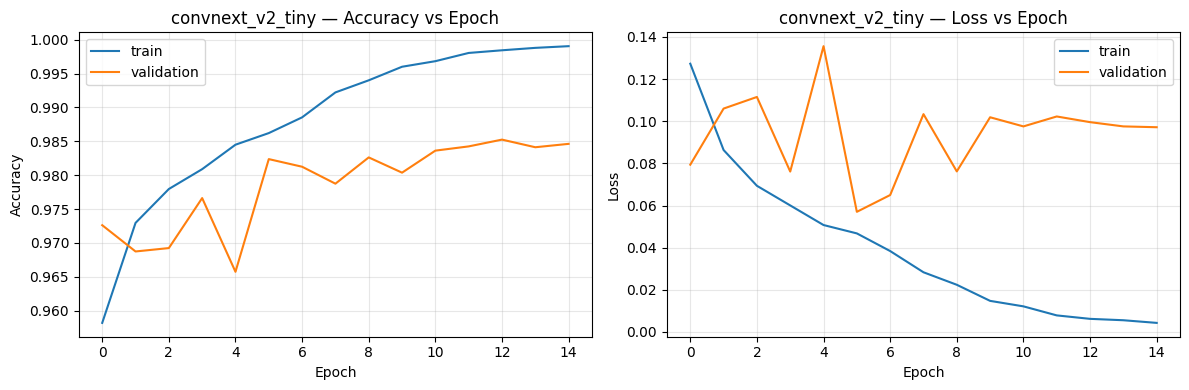

In [11]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4)
)

axes[0].plot(
    history["train_acc"],
    label="train"
)
axes[0].plot(
    history["val_acc"],
    label="validation"
)
axes[0].set_title(
    f"{MODEL_KEY} — Accuracy vs Epoch"
)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    history["train_loss"],
    label="train"
)
axes[1].plot(
    history["val_loss"],
    label="validation"
)
axes[1].set_title(
    f"{MODEL_KEY} — Loss vs Epoch"
)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "figures",
        f"{MODEL_KEY}_training_curves.png"
    ),
    dpi=150
)

plt.show()

## 10. Final evaluation on the test set

In [12]:
preds, crack_probs, labels, avg_inf_time = full_evaluate(
    model,
    test_loader
)

# Canonical encoding:
# 1 = crack
# 0 = no_crack
labels_crack = (
    labels == CRACK_IDX
).astype(int)

preds_crack = (
    preds == CRACK_IDX
).astype(int)

acc = accuracy_score(
    labels_crack,
    preds_crack
)

prec = precision_score(
    labels_crack,
    preds_crack,
    zero_division=0
)

rec = recall_score(
    labels_crack,
    preds_crack,
    zero_division=0
)

f1 = f1_score(
    labels_crack,
    preds_crack,
    zero_division=0
)

auc = roc_auc_score(
    labels_crack,
    crack_probs
)

cm = confusion_matrix(
    labels_crack,
    preds_crack,
    labels=[0, 1]
)

fpr, tpr, thresholds = roc_curve(
    labels_crack,
    crack_probs
)

n_params = sum(
    p.numel()
    for p in model.parameters()
)

print("=" * 70)
print("CLASSIFICATION REPORT")
print("0 = no_crack, 1 = crack")
print("=" * 70)

print(
    classification_report(
        labels_crack,
        preds_crack,
        target_names=[
            "no_crack",
            "crack"
        ],
        zero_division=0
    )
)

result_row = {
    "Model": MODEL_KEY,
    "Accuracy": round(acc, 4),
    "Precision (crack)": round(prec, 4),
    "Recall (crack)": round(rec, 4),
    "F1-Score (crack)": round(f1, 4),
    "ROC-AUC": round(auc, 4),
    "Training Time (s)": round(
        training_time,
        1
    ),
    "Avg Inference Time (s/img)": round(
        avg_inf_time,
        6
    ),
    "Params (M)": round(
        n_params / 1e6,
        2
    )
}

results_df = pd.DataFrame(
    [result_row]
).set_index("Model")

metrics_path = os.path.join(
    OUTPUT_DIR,
    f"{MODEL_KEY}_final_metrics.csv"
)

results_df.to_csv(metrics_path)

print(results_df)

CLASSIFICATION REPORT
0 = no_crack, 1 = crack
              precision    recall  f1-score   support

    no_crack       0.98      0.99      0.98      2000
       crack       0.99      0.98      0.98      2000

    accuracy                           0.98      4000
   macro avg       0.98      0.98      0.98      4000
weighted avg       0.98      0.98      0.98      4000

                  Accuracy  Precision (crack)  Recall (crack)  \
Model                                                           
convnext_v2_tiny    0.9842             0.9879          0.9805   

                  F1-Score (crack)  ROC-AUC  Training Time (s)  \
Model                                                            
convnext_v2_tiny            0.9842   0.9975             4806.2   

                  Avg Inference Time (s/img)  Params (M)  
Model                                                     
convnext_v2_tiny                    0.003294       27.87  


## 11. Confusion matrix

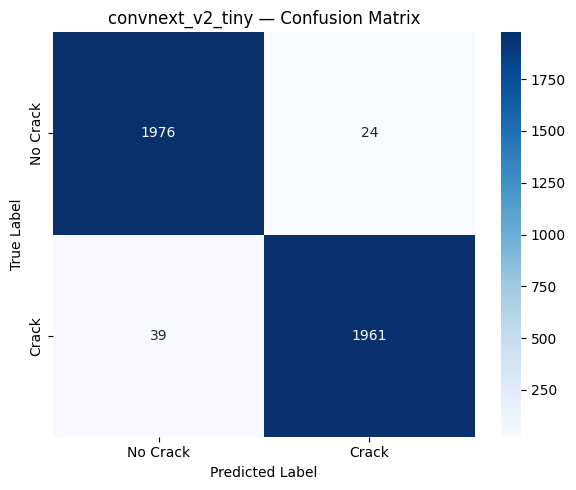

In [22]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Crack",
        "Crack"
    ],
    yticklabels=[
        "No Crack",
        "Crack"
    ]
)

plt.title(
    f"{MODEL_KEY} — Confusion Matrix"
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "figures",
        f"{MODEL_KEY}_confusion_matrix.png"
    ),
    dpi=150
)

plt.show()

## 12. ROC curve

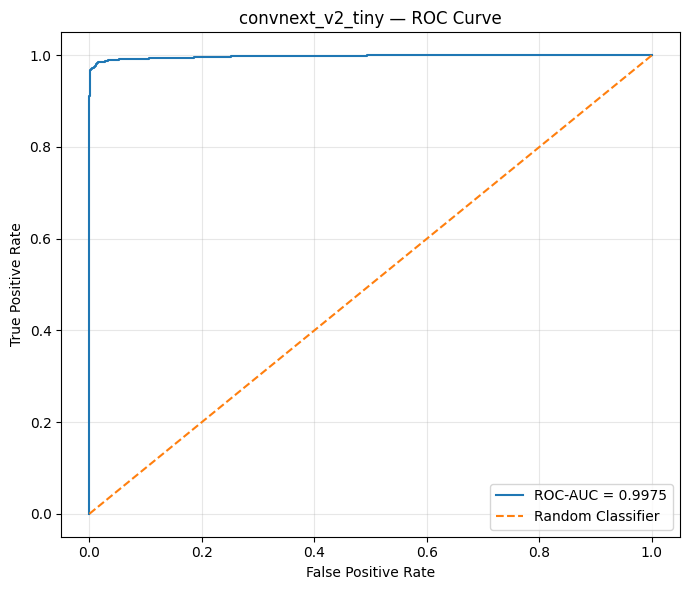

In [14]:
plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(
    f"{MODEL_KEY} — ROC Curve"
)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "figures",
        f"{MODEL_KEY}_roc_curve.png"
    ),
    dpi=150
)

plt.show()

roc_df = pd.DataFrame({
    "False Positive Rate": fpr,
    "True Positive Rate": tpr,
    "Threshold": thresholds
})

roc_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        f"{MODEL_KEY}_roc_curve.csv"
    ),
    index=False
)

## 13. Calibration check

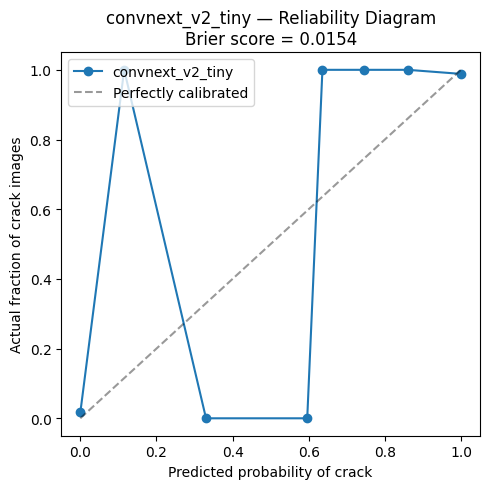

Brier score: 0.0154


In [15]:
prob_true, prob_pred = calibration_curve(
    labels_crack,
    crack_probs,
    n_bins=10,
    strategy="uniform"
)

brier = brier_score_loss(
    labels_crack,
    crack_probs
)

plt.figure(figsize=(5, 5))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label=MODEL_KEY
)

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    alpha=0.4,
    label="Perfectly calibrated"
)

plt.xlabel(
    "Predicted probability of crack"
)
plt.ylabel(
    "Actual fraction of crack images"
)

plt.title(
    f"{MODEL_KEY} — Reliability Diagram\n"
    f"Brier score = {brier:.4f}"
)

plt.legend()
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "figures",
        f"{MODEL_KEY}_calibration.png"
    ),
    dpi=150
)

plt.show()

print(
    f"Brier score: {brier:.4f}"
)

results_df["Brier Score"] = round(
    brier,
    4
)

results_df.to_csv(
    metrics_path
)

## 14. Failure case analysis

In [16]:
test_paths = [
    p for p, _ in test_ds.samples
]

misclassified_idx = np.where(
    preds_crack != labels_crack
)[0]

false_positives = [
    i for i in misclassified_idx
    if preds_crack[i] == 1
    and labels_crack[i] == 0
]

false_negatives = [
    i for i in misclassified_idx
    if preds_crack[i] == 0
    and labels_crack[i] == 1
]

print(
    f"{MODEL_KEY}: "
    f"{len(misclassified_idx)} misclassified "
    f"out of {len(labels_crack)} "
    f"({len(misclassified_idx)/len(labels_crack)*100:.2f}%)"
)

print(
    "False positives:",
    len(false_positives)
)

print(
    "False negatives:",
    len(false_negatives)
)

convnext_v2_tiny: 63 misclassified out of 4000 (1.57%)
False positives: 24
False negatives: 39


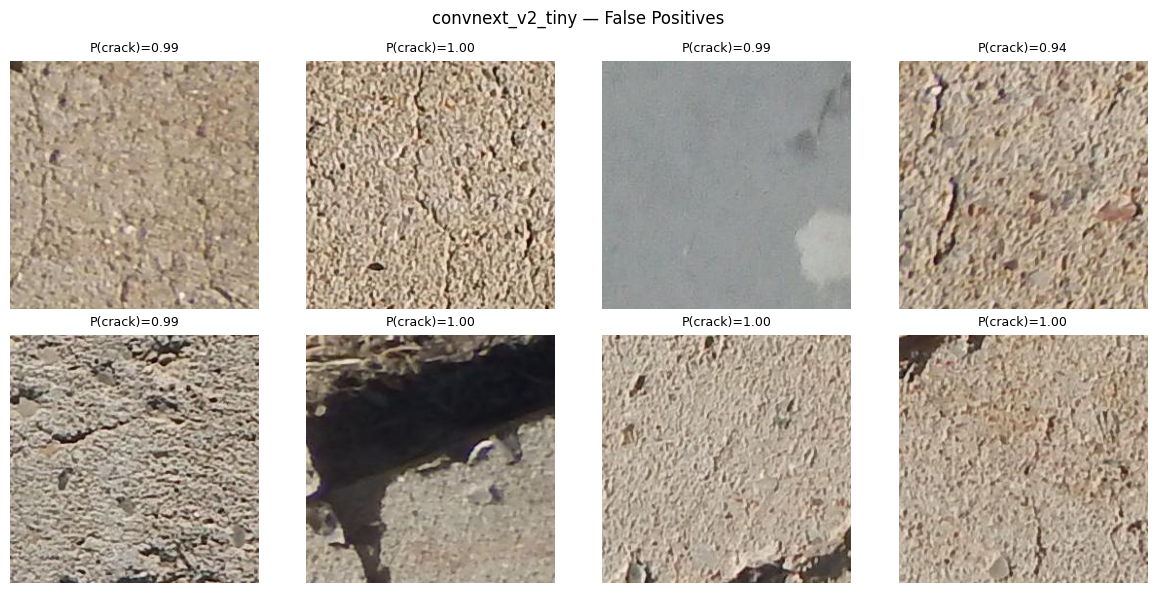

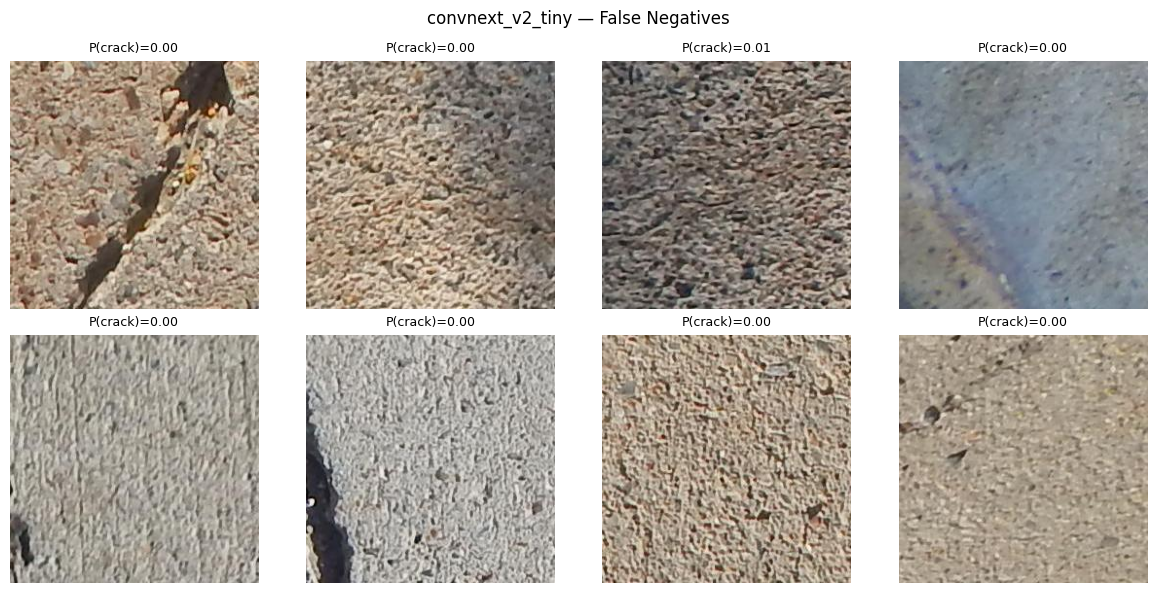

In [17]:
def show_failure_grid(
    indices,
    title,
    max_images=8
):
    n = min(
        len(indices),
        max_images
    )

    if n == 0:
        print(
            "No examples to show for:",
            title
        )
        return

    cols = 4
    rows = (
        n + cols - 1
    ) // cols

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(
            3 * cols,
            3 * rows
        )
    )

    axes = np.atleast_1d(
        axes
    ).reshape(-1)

    for ax_i, ax in enumerate(axes):

        ax.axis("off")

        if ax_i < n:

            idx = indices[ax_i]

            img = Image.open(
                test_paths[idx]
            ).convert("RGB")

            ax.imshow(img)

            ax.set_title(
                f"P(crack)={crack_probs[idx]:.2f}",
                fontsize=9
            )

    plt.suptitle(title)
    plt.tight_layout()

    safe_name = (
        title.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace(",", "")
        .replace("-", "")
    )

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "figures",
            f"{MODEL_KEY}_{safe_name}.png"
        ),
        dpi=150
    )

    plt.show()

show_failure_grid(
    false_positives,
    f"{MODEL_KEY} — False Positives"
)

show_failure_grid(
    false_negatives,
    f"{MODEL_KEY} — False Negatives"
)

## 15. Grad-CAM explainability

Run this section **after successful training**.

The final ConvNeXt V2 block is used as the target layer. The reshape function handles either NCHW or NHWC activations.

In [18]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

print(
    "Dataset class mapping:",
    test_ds.class_to_idx
)

target_layers = [
    model.stages[-1].blocks[-1]
]


def convnext_reshape_transform(tensor):

    if tensor.ndim != 4:
        raise ValueError(
            "Expected 4D activation, got "
            f"{tuple(tensor.shape)}"
        )

    # NCHW: channels are usually much larger than width.
    if tensor.shape[1] > tensor.shape[-1]:
        return tensor

    # NHWC -> NCHW
    return tensor.permute(
        0, 3, 1, 2
    )


def show_gradcam(
    image_path,
    target_class=None
):

    model.eval()

    actual_class = os.path.basename(
        os.path.dirname(image_path)
    )

    img = Image.open(
        image_path
    ).convert("RGB")

    input_tensor = eval_tfms(
        img
    ).unsqueeze(0).to(DEVICE)

    with torch.no_grad():

        output = model(
            input_tensor
        )

        probabilities = torch.softmax(
            output,
            dim=1
        )

        predicted_class = (
            output.argmax(dim=1).item()
        )

    class_names = test_ds.classes

    predicted_name = (
        class_names[predicted_class]
    )

    confidence = (
        probabilities[
            0,
            predicted_class
        ].item()
        * 100
    )

    print(
        f"Actual: {actual_class} | "
        f"Predicted: {predicted_name} | "
        f"Confidence: {confidence:.2f}%"
    )

    if target_class is None:
        target_class = predicted_class

    target_name = (
        class_names[target_class]
    )

    targets = [
        ClassifierOutputTarget(
            target_class
        )
    ]

    cam = GradCAM(
        model=model,
        target_layers=target_layers,
        reshape_transform=(
            convnext_reshape_transform
        )
    )

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0]

    rgb_img = np.asarray(
        img.resize(
            (IMG_SIZE, IMG_SIZE)
        )
    ).astype(
        np.float32
    ) / 255.0

    visualization = show_cam_on_image(
        rgb_img,
        grayscale_cam,
        use_rgb=True
    )

    plt.figure(figsize=(6, 6))

    plt.imshow(
        visualization
    )

    plt.title(
        f"{MODEL_KEY} Grad-CAM\n"
        f"Actual: {actual_class} | "
        f"Predicted: {predicted_name} "
        f"({confidence:.1f}%)\n"
        f"Explaining class: {target_name}"
    )

    plt.axis("off")
    plt.tight_layout()
    plt.show()

    return visualization

Dataset class mapping: {'crack': 0, 'no_crack': 1}


Crack example:
Actual: crack | Predicted: crack | Confidence: 100.00%


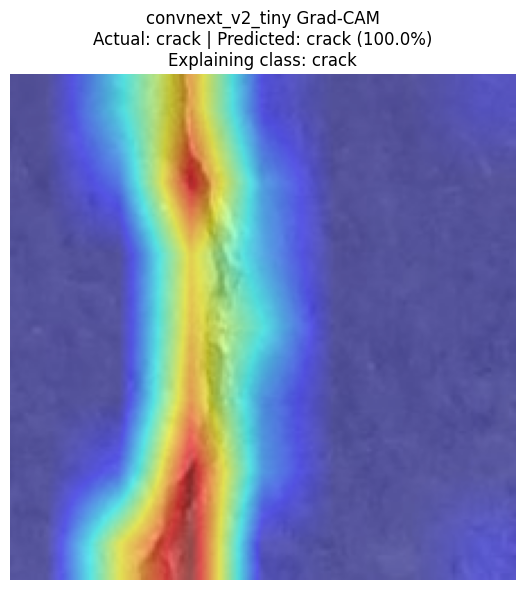


No-crack example:
Actual: no_crack | Predicted: no_crack | Confidence: 100.00%


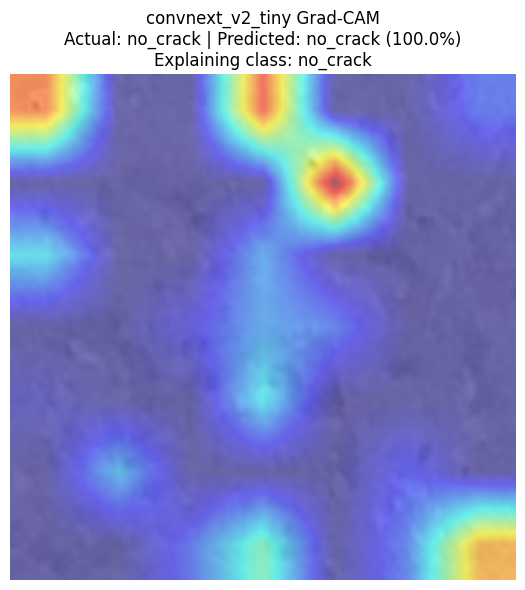

array([[[239, 141,  93],
        [238, 140,  93],
        [238, 140,  93],
        ...,
        [105, 128, 234],
        [105, 128, 234],
        [104, 127, 233]],

       [[240, 142,  94],
        [240, 142,  94],
        [240, 141,  94],
        ...,
        [104, 127, 233],
        [104, 127, 233],
        [103, 126, 232]],

       [[241, 143,  95],
        [241, 143,  95],
        [241, 142,  95],
        ...,
        [104, 127, 233],
        [104, 127, 233],
        [103, 126, 232]],

       ...,

       [[103,  98, 161],
        [103,  98, 161],
        [103,  98, 161],
        ...,
        [244, 182,  98],
        [244, 182,  98],
        [244, 182,  98]],

       [[103,  98, 161],
        [103,  98, 161],
        [103,  98, 161],
        ...,
        [244, 182,  98],
        [244, 182,  98],
        [244, 182,  98]],

       [[103,  98, 161],
        [103,  98, 161],
        [103,  98, 161],
        ...,
        [244, 182,  98],
        [244, 182,  98],
        [244, 182,  98]]

In [19]:
crack_path = next(
    p for p, l in test_ds.samples
    if l == CRACK_IDX
)

no_crack_path = next(
    p for p, l in test_ds.samples
    if l == NO_CRACK_IDX
)

print("Crack example:")
show_gradcam(
    crack_path
)

print("\nNo-crack example:")
show_gradcam(
    no_crack_path
)

## 16. Saved files

In [20]:
print("Best checkpoint:")
print(best_path)

print("\nTraining history:")
print(history_path)

print("\nFinal metrics:")
print(metrics_path)

print("\nEpoch log:")
print(csv_log_path)

print("\nFigures folder:")
print(
    os.path.join(
        OUTPUT_DIR,
        "figures"
    )
)

Best checkpoint:
C:\Users\Students\Desktop\Crack classification(Indhu)\Output\checkpoints\convnext_v2_tiny_best.pt

Training history:
C:\Users\Students\Desktop\Crack classification(Indhu)\Output\logs\convnext_v2_tiny_history.json

Final metrics:
C:\Users\Students\Desktop\Crack classification(Indhu)\Output\convnext_v2_tiny_final_metrics.csv

Epoch log:
C:\Users\Students\Desktop\Crack classification(Indhu)\Output\logs\convnext_v2_tiny_epoch_log.csv

Figures folder:
C:\Users\Students\Desktop\Crack classification(Indhu)\Output\figures


## Final interpretation rule

Do not use the old notebook's 50% accuracy as a ConvNeXt result. That run had `NaN` loss from Epoch 4 onward and predicted `no_crack` for every test image.

For this corrected run, first verify:
- loss stays finite,
- validation accuracy rises clearly above 50%,
- both classes are predicted,
- the best validation checkpoint is used for test evaluation.

Only then use the Accuracy, Precision, Recall, F1, ROC-AUC, calibration, failure analysis, and Grad-CAM results in the final comparison with your other models.